# FNO

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from project_runtime import select_device

from neural_operators import (
    ChebyshevCommittor,
    DataConfig,
    DeepONet,
    FNO1D,
    GaussianRandomField,
    TrainingConfig,
    compare_operators,
    make_splits,
    plot_predictions,
    plot_rmse_comparison,
    plot_training,
    save_splits,
)

plt.rcParams.update({'font.size': 13})
torch.manual_seed(0)
device = select_device()
print(f'Compute device: {device}')
output_dir = Path.cwd() / 'outputs' / 'neural_operators'
output_dir.mkdir(parents=True, exist_ok=True)

Compute device: cuda


In [2]:
beta = 1.0
x_bounds = (-1.0, 1.0)
sensor_grid = np.linspace(*x_bounds, 128)
parameter_bounds = np.array([[0.0, 5.0], [-0.5, 0.5], [0.25, 0.7]])
length_scale = 0.5

def parametric_force(x, parameters):
    x = np.asarray(x)[None, :]
    amplitude = parameters[:, 0:1]
    center = parameters[:, 1:2]
    width = parameters[:, 2:3]
    gaussian = np.exp(-0.5 * ((x - center) / width)**2)
    return 4*x**3 - 4*x - amplitude * (x - center) * gaussian / width**2

In [3]:
grf = GaussianRandomField(sensor_grid, length_scale=length_scale)

def sample_parametric(n_functions, rng):
    parameters = rng.uniform(parameter_bounds[:, 0], parameter_bounds[:, 1], size=(n_functions, 3))
    return parameters, parametric_force(sensor_grid, parameters)

def sample_grf(n_functions, rng):
    forces = grf.sample(n_functions, rng)
    return forces, forces

samplers = {'Parametric': sample_parametric, 'GRF': sample_grf}

In [4]:
data_config = DataConfig(
    n_train=2000, n_validation=200, n_test=1000,
    n_queries=100, n_evaluation=257, seed=0,
)
solver = ChebyshevCommittor(degree=64, beta=beta, x_bounds=x_bounds)
datasets = {}
for family, sampler in samplers.items():
    datasets[family] = make_splits(sampler, sensor_grid, solver, data_config)
    save_splits(datasets[family], output_dir / f'{family}_data.npz')

In [5]:
models = {}
for family, data in datasets.items():
    models[family] = {
        'DeepONet': DeepONet(
            branch_size=data.train.branch_inputs.shape[1], latent_size=40,
            branch_width=80, trunk_width=40, x_bounds=x_bounds,
        ),
        'FNO': FNO1D(width=32, modes=16, n_layers=4, x_bounds=x_bounds),
    }
training_config = TrainingConfig(
    epochs=600, batch_size=64, learning_rate=1e-3,
    minimum_learning_rate=1e-5, validation_every=10, seed=0,
)

In [6]:
results = {}
for family, data in datasets.items():
    print(f'{family} problem')
    results[family] = compare_operators(models[family], data, training_config, output_dir / family)

Parametric problem
Training DeepONet
Epoch 0: train RMSE=1.202e-01, validation RMSE=9.584e-02
Epoch 50: train RMSE=2.651e-02, validation RMSE=2.934e-02
Epoch 100: train RMSE=1.716e-02, validation RMSE=1.815e-02
Epoch 150: train RMSE=1.365e-02, validation RMSE=1.319e-02
Epoch 200: train RMSE=1.143e-02, validation RMSE=1.078e-02
Epoch 250: train RMSE=9.835e-03, validation RMSE=1.052e-02
Epoch 300: train RMSE=8.715e-03, validation RMSE=8.656e-03
Epoch 350: train RMSE=7.887e-03, validation RMSE=7.859e-03
Epoch 400: train RMSE=7.163e-03, validation RMSE=7.336e-03
Epoch 450: train RMSE=6.591e-03, validation RMSE=6.471e-03
Epoch 500: train RMSE=6.397e-03, validation RMSE=6.163e-03
Epoch 550: train RMSE=6.214e-03, validation RMSE=6.163e-03
Epoch 599: train RMSE=6.124e-03, validation RMSE=6.059e-03
DeepONet: train RMSE=6.117e-03, test RMSE=6.354e-03
Training FNO
Epoch 0: train RMSE=7.895e-02, validation RMSE=2.696e-02
Epoch 50: train RMSE=1.092e-03, validation RMSE=1.797e-03
Epoch 100: train RM

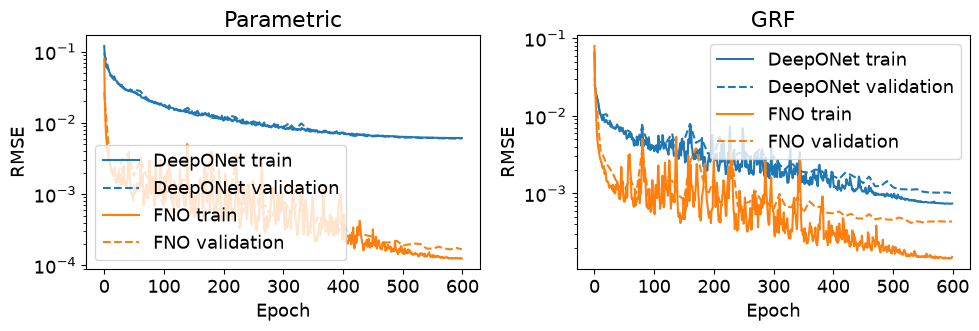

In [7]:
fig, axes = plot_training(results)
fig.savefig(output_dir / 'training.pdf')
plt.show()

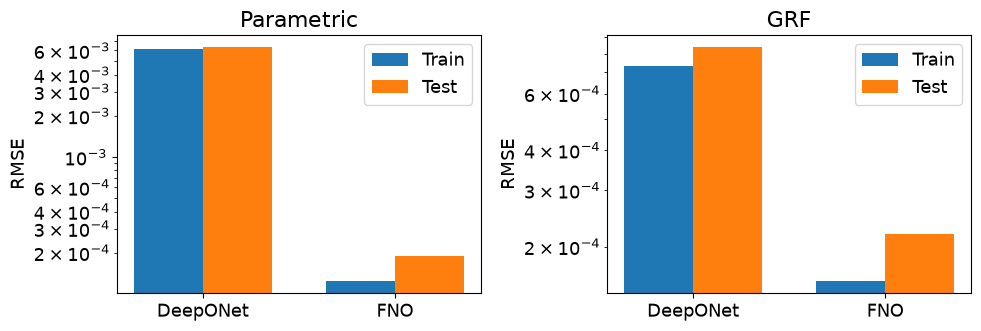

In [8]:
fig, axes = plot_rmse_comparison(results)
fig.savefig(output_dir / 'rmse_comparison.pdf')
plt.show()

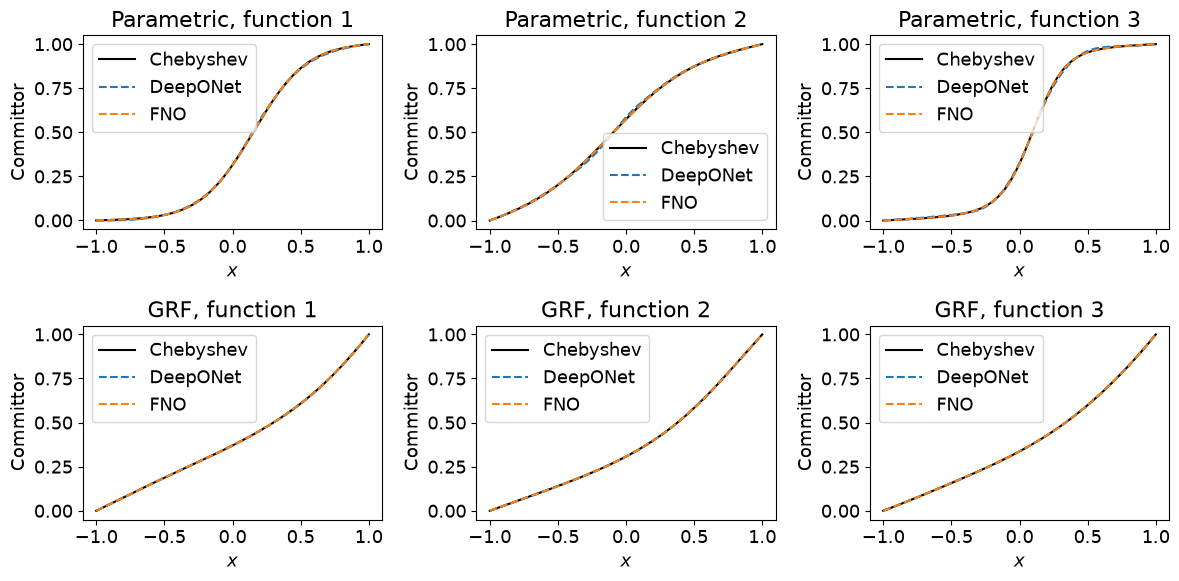

In [9]:
fig, axes = plot_predictions(results, datasets, n_examples=3)
fig.savefig(output_dir / 'predictions.pdf')
plt.show()